<a href="https://colab.research.google.com/github/Sonali-Kumari249/Java-Notes/blob/main/miniproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

# 1. Download a real credit card fraud dataset provided by Google
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
data = pd.read_csv(url)

# 2. Show the first 5 rows of our data
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# Count how many normal (0) and fraud (1) transactions there are
print(data['Class'].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [4]:
from sklearn.preprocessing import StandardScaler

# Shrink the Time and Amount columns so the AI can read them easily
scaler = StandardScaler()
data['Amount'] = scaler.fit_transform(data[['Amount']])
data['Time'] = scaler.fit_transform(data[['Time']])

print("Data is scaled and 100% ready for the AI!")

Data is scaled and 100% ready for the AI!


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Separate the "Answers" (Class) from the "Clues" (Time, Amount, V1-V28)
X = data.drop('Class', axis=1) # The Clues
y = data['Class']              # The Answers

# 2. Split the data: 80% to study, 20% for the test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Bring in a standard AI model and tell it to study!
print("AI is studying... please wait a few seconds...")
ai_model = LogisticRegression()
ai_model.fit(X_train, y_train)

# 4. Give the AI the test data and check its score
predictions = ai_model.predict(X_test)
score = accuracy_score(y_test, predictions)

print(f"Done! The AI scored: {score * 100:.2f}% accuracy on the test!")

AI is studying... please wait a few seconds...
Done! The AI scored: 99.91% accuracy on the test!


In [6]:
from sklearn.metrics import classification_report

print("Detailed Report Card:")
print(classification_report(y_test, predictions))

Detailed Report Card:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.86      0.60      0.71        98

    accuracy                           1.00     56962
   macro avg       0.93      0.80      0.85     56962
weighted avg       1.00      1.00      1.00     56962



In [7]:
# 1. Sort all data by the 'Amount' column
sorted_data = data.sort_values(by='Amount')

# 2. Chop the data into 3 equal pieces
chunk_size = len(sorted_data) // 3
bank_a = sorted_data.iloc[:chunk_size]
bank_b = sorted_data.iloc[chunk_size:2*chunk_size]
bank_c = sorted_data.iloc[2*chunk_size:]

# 3. Let's see how many frauds ended up in each bank!
print("Frauds hiding in Bank A (Small transactions):", bank_a['Class'].sum())
print("Frauds hiding in Bank B (Medium transactions):", bank_b['Class'].sum())
print("Frauds hiding in Bank C (Large transactions):", bank_c['Class'].sum())

Frauds hiding in Bank A (Small transactions): 249
Frauds hiding in Bank B (Medium transactions): 56
Frauds hiding in Bank C (Large transactions): 187


In [8]:
import warnings
warnings.filterwarnings('ignore') # Hides annoying red warning text

print("Banks are training their local models securely...")
# Train Bank A
X_a, y_a = bank_a.drop('Class', axis=1), bank_a['Class']
model_a = LogisticRegression(max_iter=1000).fit(X_a, y_a)

# Train Bank B
X_b, y_b = bank_b.drop('Class', axis=1), bank_b['Class']
model_b = LogisticRegression(max_iter=1000).fit(X_b, y_b)

# Train Bank C
X_c, y_c = bank_c.drop('Class', axis=1), bank_c['Class']
model_c = LogisticRegression(max_iter=1000).fit(X_c, y_c)

print("Central Server is averaging their knowledge (FedAvg)...")
# Create an empty Global Model
global_model = LogisticRegression(max_iter=1000)
global_model.fit(X_test[:2], y_test[:2]) # Just to set it up

# THE MAGIC: Average the math (weights) from all 3 banks
global_model.coef_ = (model_a.coef_ + model_b.coef_ + model_c.coef_) / 3
global_model.intercept_ = (model_a.intercept_ + model_b.intercept_ + model_c.intercept_) / 3

# Give the new Global AI the final exam!
print("\nGlobal AI Report Card:")
global_predictions = global_model.predict(X_test)
print(classification_report(y_test, global_predictions))

Banks are training their local models securely...
Central Server is averaging their knowledge (FedAvg)...

Global AI Report Card:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56864
           1       0.13      0.66      0.21        98

    accuracy                           0.99     56962
   macro avg       0.56      0.83      0.60     56962
weighted avg       1.00      0.99      0.99     56962



Testing the Privacy-Utility Trade-off...

Privacy Noise Level 0: AI caught 66.3% of frauds
Privacy Noise Level 0.5: AI caught 53.1% of frauds
Privacy Noise Level 1.0: AI caught 90.8% of frauds
Privacy Noise Level 2.0: AI caught 73.5% of frauds
Privacy Noise Level 5.0: AI caught 90.8% of frauds
Privacy Noise Level 10.0: AI caught 4.1% of frauds


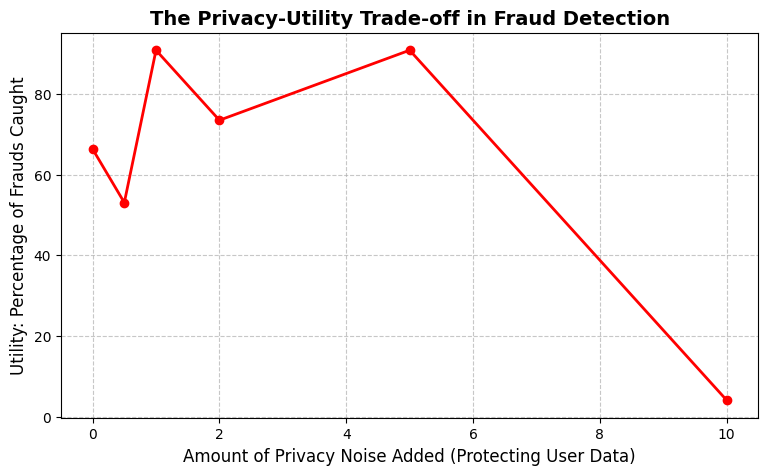

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import recall_score

# Different levels of "Privacy Blur" we want to test
noise_levels = [0, 0.5, 1.0, 2.0, 5.0, 10.0]
frauds_caught = []

# Save the original, clear brain of our Global AI
original_weights = global_model.coef_.copy()

print("Testing the Privacy-Utility Trade-off...\n")

for noise in noise_levels:
    # 1. Inject random Gaussian Noise (The 'Differential Privacy' blur)
    blurred_weights = original_weights + np.random.normal(0, noise, original_weights.shape)

    # 2. Put the blurred brain back into the AI
    global_model.coef_ = blurred_weights

    # 3. Give it the exam and see how many frauds it catches now
    preds = global_model.predict(X_test)
    recall = recall_score(y_test, preds) * 100
    frauds_caught.append(recall)

    print(f"Privacy Noise Level {noise}: AI caught {recall:.1f}% of frauds")

# 4. Draw the final Research Graph!
plt.figure(figsize=(9, 5))
plt.plot(noise_levels, frauds_caught, marker='o', color='red', linewidth=2)
plt.title("The Privacy-Utility Trade-off in Fraud Detection", fontsize=14, fontweight='bold')
plt.xlabel("Amount of Privacy Noise Added (Protecting User Data)", fontsize=12)
plt.ylabel("Utility: Percentage of Frauds Caught", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()